In [2]:
import pandas as pd
df = pd.read_csv("/content/sales_working.csv")
df["Order Date"] = pd.to_datetime(df["Order Date"], dayfirst=True)
df = df[["Order Date", "Sales"]].dropna()
df.info()
monthly = df.set_index("Order Date").resample("MS")["Sales"].sum().reset_index()
monthly.columns = ["Month", "Sales"]
monthly.head(), len(monthly)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Order Date  9800 non-null   datetime64[ns]
 1   Sales       9800 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 153.3 KB


(       Month      Sales
 0 2015-01-01  14205.707
 1 2015-02-01   4519.892
 2 2015-03-01  55205.797
 3 2015-04-01  27906.855
 4 2015-05-01  23644.303,
 48)

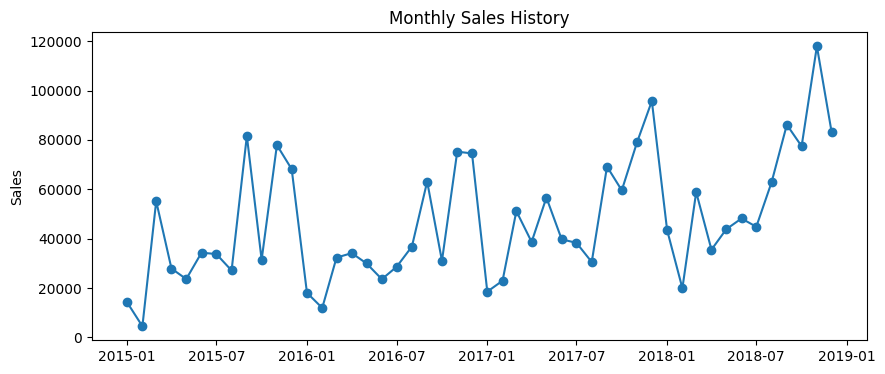

In [3]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,4))
plt.plot(monthly["Month"], monthly["Sales"], marker="o")
plt.title("Monthly Sales History")
plt.ylabel("Sales")
plt.show()

Model MAE: 14681 | RMSE: 18498 | MAPE %: 17.7
Baseline MAE: 36103


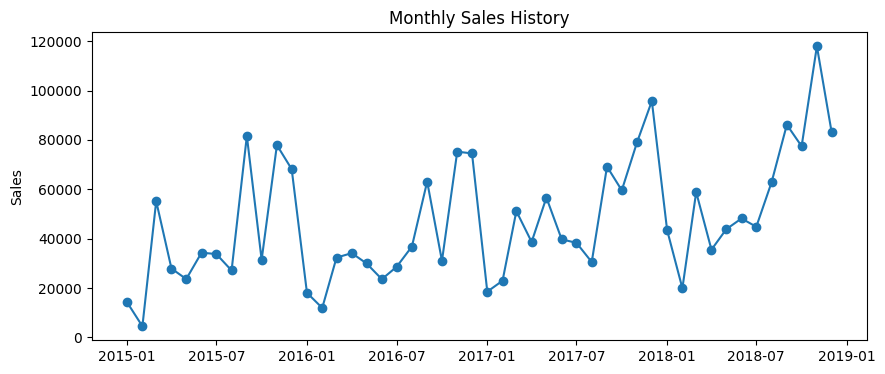

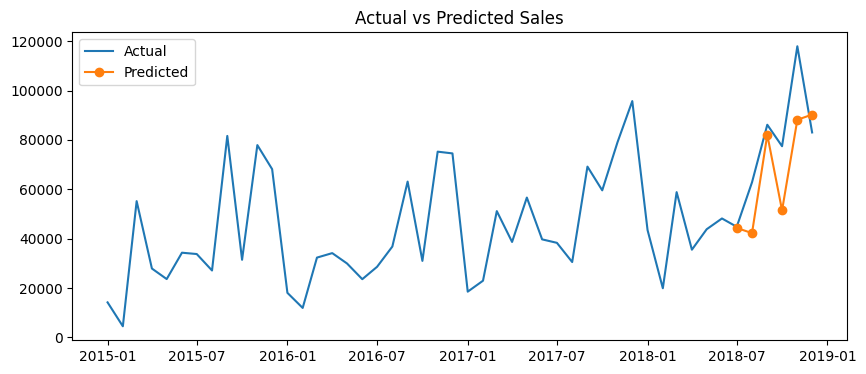

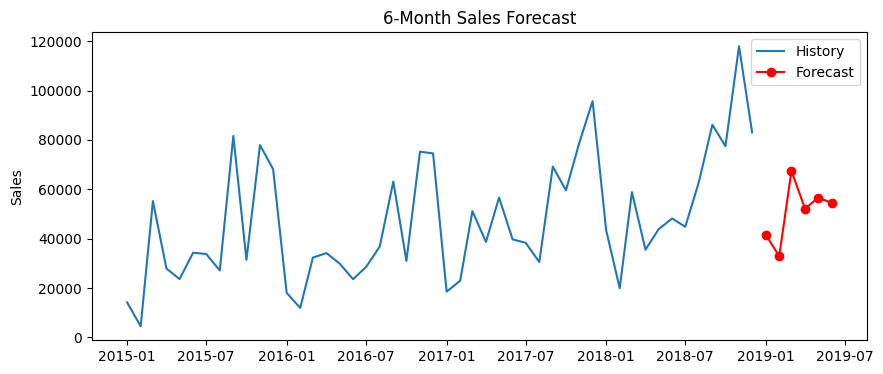

      Month  Forecast
0  Jan 2019   41643.0
1  Feb 2019   32912.0
2  Mar 2019   67463.0
3  Apr 2019   52140.0
4  May 2019   56591.0
5  Jun 2019   54529.0


In [8]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# Load and clean
df = pd.read_csv("/content/sales_working.csv")
df["Order Date"] = pd.to_datetime(df["Order Date"], dayfirst=True)
df = df[["Order Date", "Sales"]].dropna()

# Monthly aggregation
monthly = df.set_index("Order Date").resample("MS")["Sales"].sum().reset_index()
monthly.columns = ["Month", "Sales"]
monthly["t"] = range(len(monthly))
monthly["month"] = monthly["Month"].dt.month

# Features
X = pd.get_dummies(monthly[["t", "month"]], columns=["month"], drop_first=True)
y = monthly["Sales"]

# Train/test split by time
X_train, X_test = X[:-6], X[-6:]
y_train, y_test = y[:-6], y[-6:]
model = LinearRegression().fit(X_train, y_train)
pred = model.predict(X_test)

mae = np.mean(abs(y_test - pred))
rmse = np.sqrt(np.mean((y_test - pred) ** 2))
mape = np.mean(abs((y_test - pred) / y_test)) * 100
base_mae = np.mean(abs(y_test - y_train.mean()))
print("Model MAE:", round(mae), "| RMSE:", round(rmse), "| MAPE %:", round(mape, 1))
print("Baseline MAE:", round(base_mae))

# Chart 1: history
plt.figure(figsize=(10, 4))
plt.plot(monthly["Month"], y, marker="o")
plt.title("Monthly Sales History"); plt.ylabel("Sales"); plt.show()

# Chart 2: actual vs predicted
plt.figure(figsize=(10, 4))
plt.plot(monthly["Month"], y, label="Actual")
plt.plot(monthly["Month"][-6:], pred, label="Predicted", marker="o")
plt.legend(); plt.title("Actual vs Predicted Sales"); plt.show()

# Forecast next 6 months
future_dates = pd.date_range(monthly["Month"].iloc[-1] + pd.offsets.MonthBegin(1), periods=6, freq="MS")
future = pd.DataFrame({"t": range(len(monthly), len(monthly) + 6), "month": future_dates.month})
Xf = pd.get_dummies(future, columns=["month"], drop_first=True).reindex(columns=X.columns, fill_value=0)
fc = LinearRegression().fit(X, y).predict(Xf)

plt.figure(figsize=(10, 4))
plt.plot(monthly["Month"], y, label="History")
plt.plot(future_dates, fc, label="Forecast", marker="o", color="red")
plt.legend(); plt.title("6-Month Sales Forecast"); plt.ylabel("Sales"); plt.show()

print(pd.DataFrame({"Month": future_dates.strftime("%b %Y"), "Forecast": fc.round(0)}))


In [4]:
monthly["t"] = range(len(monthly))
monthly["month"] = monthly["Month"].dt.month
X = pd.get_dummies(monthly[["t","month"]], columns=["month"], drop_first=True)
y = monthly["Sales"]

In [5]:
from sklearn.linear_model import LinearRegression
import numpy as np

X_train, X_test = X[:-6], X[-6:]
y_train, y_test = y[:-6], y[-6:]

model = LinearRegression().fit(X_train, y_train)
pred = model.predict(X_test)

mae = np.mean(abs(y_test - pred))
rmse = np.sqrt(np.mean((y_test - pred)**2))
mape = np.mean(abs((y_test - pred) / y_test)) * 100

# Baseline: predict the training average
base_mae = np.mean(abs(y_test - y_train.mean()))

print("Model MAE:", round(mae))
print("Model RMSE:", round(rmse))
print("Model MAPE %:", round(mape, 1))
print("Baseline MAE:", round(base_mae))

Model MAE: 14681
Model RMSE: 18498
Model MAPE %: 17.7
Baseline MAE: 36103


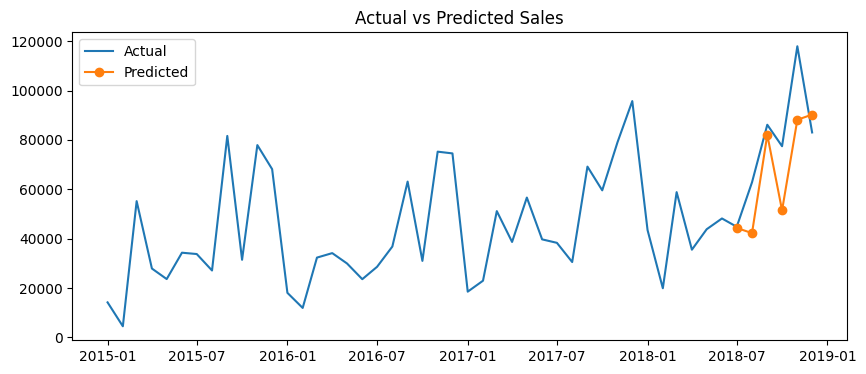

In [6]:
plt.figure(figsize=(10,4))
plt.plot(monthly["Month"], y, label="Actual")
plt.plot(monthly["Month"][-6:], pred, label="Predicted", marker="o")
plt.legend()
plt.title("Actual vs Predicted Sales")
plt.show()

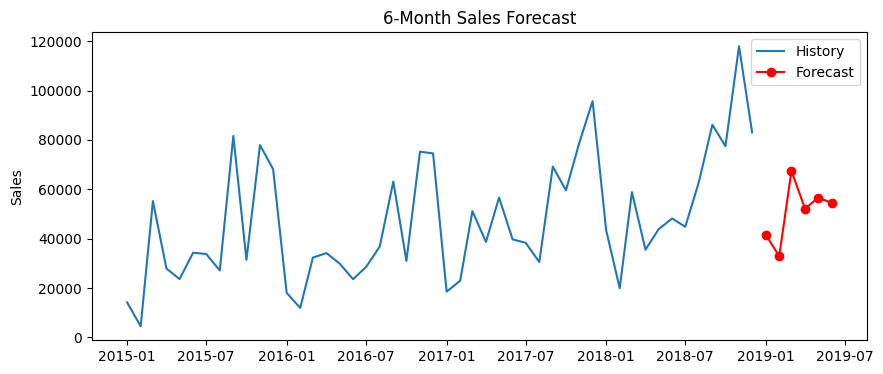

,Month,Forecast
0,2019-01-01,41643.0
1,2019-02-01,32912.0
2,2019-03-01,67463.0
3,2019-04-01,52140.0
4,2019-05-01,56591.0
5,2019-06-01,54529.0


In [7]:
last_t = monthly["t"].iloc[-1]
future = pd.DataFrame({"t": range(last_t + 1, last_t + 7)})
future_dates = pd.date_range(monthly["Month"].iloc[-1] + pd.offsets.MonthBegin(1), periods=6, freq="MS")
future["month"] = future_dates.month

Xf = pd.get_dummies(future, columns=["month"], drop_first=True)
Xf = Xf.reindex(columns=X.columns, fill_value=0)

# Refit on all data for the final forecast
final_model = LinearRegression().fit(X, y)
fc = final_model.predict(Xf)

plt.figure(figsize=(10,4))
plt.plot(monthly["Month"], y, label="History")
plt.plot(future_dates, fc, label="Forecast", marker="o", color="red")
plt.legend()
plt.title("6-Month Sales Forecast")
plt.ylabel("Sales")
plt.show()

pd.DataFrame({"Month": future_dates, "Forecast": fc.round(0)})